# ML-06 — Signal Audit: Do the Flags Hold?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Kifayat-Sayed/flyrank-ml-internship1/blob/main/work/notebooks/w04_signal_audit.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Distributions
### Dataset and distribution overview

I use the anonymized 30,000-row starter dataset. Each row represents one pseudonymized content item, and the activity metrics describe a trailing 90-day window.

Before testing any signal, I inspect the distributions of search impressions, clicks, sessions, search volume, content length, and update age. Traffic counts are expected to be right-skewed: a small number of content items may account for a large share of observed activity.

I report medians and upper percentiles alongside means because the mean alone can be dominated by a small number of high-volume items. I also inspect missing values and zero-position records. A value of `avg_position = 0` represents unavailable position data and is excluded from position-based comparisons.

The decline label is defined as `trend_direction == "down"`. It is used only as an observed outcome for descriptive signal tests, not as proof of future decline or causal impact.

DATASET OVERVIEW
-------------------------------------------------------
Rows: 30,000
Columns: 45
Unique pseudonymized clients: 32
Observed decline-label prevalence: 54.2%


,count,mean,std,min,25%,50%,75%,90%,95%,99%,max,missing_pct,skewness
impressions_90d,30000.0,5200.37,16838.02,1.0,81.0,731.0,3615.25,12136.4,22996.50,73505.83,517715.0,0.00,11.38
clicks_90d,30000.0,16.10,75.08,0.0,0.0,1.0,7.00,32.0,69.05,253.01,4178.0,0.00,18.35
sessions_90d,30000.0,37.07,107.07,1.0,2.0,7.0,27.00,88.0,166.00,451.01,4345.0,0.00,12.13
search_volume,27532.0,158.88,1518.27,0.0,0.0,10.0,20.00,110.0,390.00,2900.00,74000.0,8.23,26.02
word_count,22301.0,3107.76,1452.38,8.0,2413.0,2877.0,3666.00,5327.0,6173.00,7292.00,9546.0,25.66,0.94
days_since_last_update,30000.0,46.10,42.08,1.0,20.0,20.0,104.00,104.0,104.00,106.00,373.0,0.00,1.16



POSITION DATA CHECK
-------------------------------------------------------
Rows with avg_position = 0: 1,205
These rows are treated as having no position data, not as rank zero.


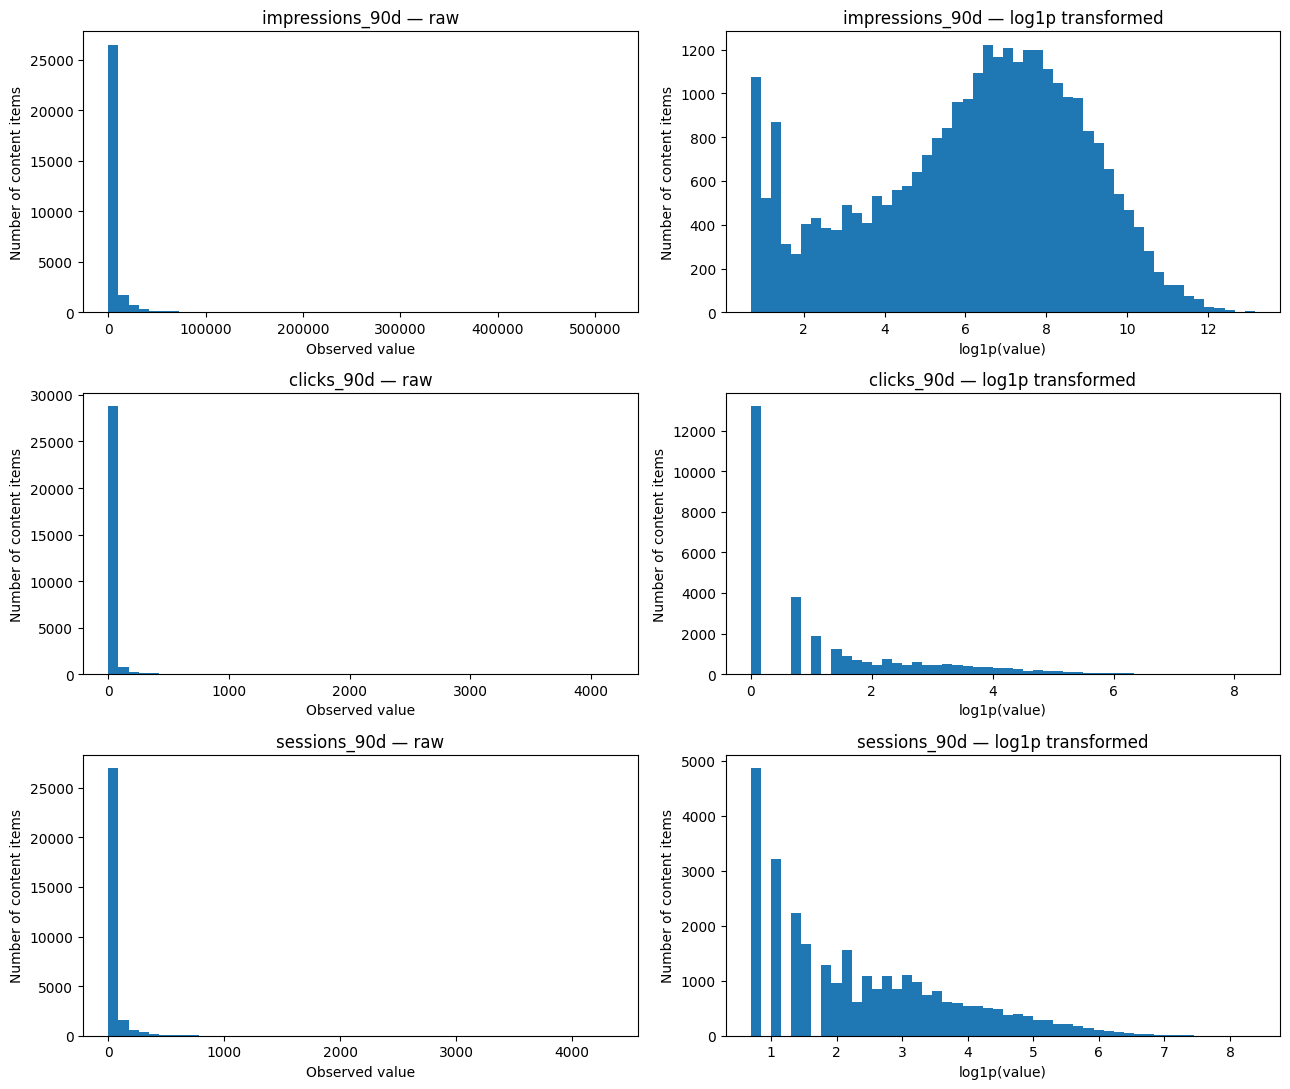


HEAVY-TAIL CHECK
-------------------------------------------------------
impressions_90d: median=731.00, 99th percentile=73,505.83
clicks_90d: median=1.00, 99th percentile=253.01
sessions_90d: median=7.00, 99th percentile=451.01

Distribution audit completed.


In [3]:
# SECTION 1 — DISTRIBUTION AUDIT

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_URL = (
    "https://raw.githubusercontent.com/"
    "Kifayat-Sayed/flyrank-ml-internship1/"
    "main/data/raw/content_refresh_anonymized.csv"
)

DATA_PATH = Path("/content/content_refresh_anonymized.csv")

if DATA_PATH.exists():
    data = pd.read_csv(DATA_PATH)
else:
    data = pd.read_csv(DATA_URL)
    data.to_csv(DATA_PATH, index=False)

required_columns = {
    "content_id",
    "client_id",
    "trend_direction",
    "impressions_90d",
    "clicks_90d",
    "sessions_90d",
    "search_volume",
    "word_count",
    "days_since_last_update",
    "avg_position",
    "ctr",
}

missing_columns = required_columns - set(data.columns)

if missing_columns:
    raise ValueError(
        f"Missing required columns: {sorted(missing_columns)}"
    )

# Descriptive target only.
data["_audit_declining"] = (
    data["trend_direction"]
    .astype("string")
    .str.strip()
    .str.lower()
    .eq("down")
    .astype("int8")
)

print("DATASET OVERVIEW")
print("-" * 55)
print(f"Rows: {len(data):,}")
print(f"Columns: {data.shape[1]:,}")
print(f"Unique pseudonymized clients: {data['client_id'].nunique():,}")
print(
    "Observed decline-label prevalence: "
    f"{data['_audit_declining'].mean():.1%}"
)

# Inspect skewed numeric fields.
distribution_columns = [
    "impressions_90d",
    "clicks_90d",
    "sessions_90d",
    "search_volume",
    "word_count",
    "days_since_last_update",
]

summary = data[distribution_columns].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).T

summary["missing_pct"] = (
    data[distribution_columns].isna().mean() * 100
)

summary["skewness"] = data[distribution_columns].skew()

display(summary.round(2))

# Check special zero-position handling.
zero_position_count = (data["avg_position"] == 0).sum()

print("\nPOSITION DATA CHECK")
print("-" * 55)
print(f"Rows with avg_position = 0: {zero_position_count:,}")
print(
    "These rows are treated as having no position data, "
    "not as rank zero."
)

# Compare raw and log-transformed traffic distributions.
traffic_columns = [
    "impressions_90d",
    "clicks_90d",
    "sessions_90d",
]

fig, axes = plt.subplots(
    nrows=len(traffic_columns),
    ncols=2,
    figsize=(13, 11)
)

for i, column in enumerate(traffic_columns):
    values = pd.to_numeric(
        data[column], errors="coerce"
    ).dropna()

    axes[i, 0].hist(values, bins=50)
    axes[i, 0].set_title(f"{column} — raw")
    axes[i, 0].set_xlabel("Observed value")
    axes[i, 0].set_ylabel("Number of content items")

    axes[i, 1].hist(np.log1p(values), bins=50)
    axes[i, 1].set_title(f"{column} — log1p transformed")
    axes[i, 1].set_xlabel("log1p(value)")
    axes[i, 1].set_ylabel("Number of content items")

plt.tight_layout()
plt.show()

# Heavy-tail check: compare median and 99th percentile.
print("\nHEAVY-TAIL CHECK")
print("-" * 55)

for column in traffic_columns:
    values = pd.to_numeric(
        data[column], errors="coerce"
    ).dropna()

    median_value = values.median()
    p99 = values.quantile(0.99)

    print(
        f"{column}: median={median_value:,.2f}, "
        f"99th percentile={p99:,.2f}"
    )

print("\nDistribution audit completed.")

## 2. Signal test #1 / #2 / #3 (verdict each)

### Signal 1 — Content staleness

**Claim:** Content that has gone longer without an update may have a higher observed decline rate.

**Test:** Group content by days since its last update and compare the proportion carrying the observed decline label. Report the number of items in each group.

**Verdict:** Determined from the measured pattern. A higher decline rate in older-update groups would support the directional assumption, but would not prove that refreshing content causes performance to improve.

### Signal 2 — Search impression volume

**Claim:** Content with higher search impression volume may have a different observed decline rate from lower-volume content.

**Test:** Group items by their existing impression tiers and compare observed decline rates. Include the sample size for every tier.

**Verdict:** Determined from the measured pattern. Impression volume describes the scale of observed search exposure; it does not by itself establish that an item is a good refresh opportunity.

### Signal 3 — Average search position

**Claim:** Content with weaker average search positions may show a higher observed decline rate.

**Test:** Exclude rows where `avg_position = 0`, then group the remaining items into position bands and compare observed decline rates.

**Verdict:** Determined from the measured pattern. Position is interpreted directionally: a larger numerical position means a weaker search position.

### Verdict rules

- **CONFIRMED:** The measured pattern follows the stated direction across adequately sized groups.
- **OPPOSITE:** The measured pattern consistently runs in the reverse direction.
- **MIXED:** The pattern is inconsistent, weak, or not sufficiently supported.

A group must contain at least 50 observations to contribute to a verdict. Small groups remain visible in the tables but are not used to justify a conclusion.

In [4]:
# SECTION 2 — THREE SIGNAL TESTS

MIN_GROUP_SIZE = 50

def signal_table(frame, group_column, ordered_groups=None):
    """
    Calculate observed decline rates with sample sizes.
    """
    result = (
        frame.groupby(group_column, observed=False)
        .agg(
            n=("_audit_declining", "size"),
            decline_rate=("_audit_declining", "mean")
        )
        .reset_index()
    )

    result["decline_rate_pct"] = (
        result["decline_rate"] * 100
    ).round(2)

    if ordered_groups is not None:
        result[group_column] = pd.Categorical(
            result[group_column],
            categories=ordered_groups,
            ordered=True
        )
        result = result.sort_values(group_column)

    return result


def assign_verdict(table, group_column, expected_direction):
    """
    Compare adequately sized groups in their intended order.
    """
    usable = table.loc[
        table["n"] >= MIN_GROUP_SIZE
    ].copy()

    if len(usable) < 2:
        return "MIXED — insufficient adequately sized groups"

    rates = usable["decline_rate"].to_numpy()

    differences = np.diff(rates)

    if expected_direction == "increasing":
        confirmed = np.all(differences >= 0) and (
            rates[-1] - rates[0] >= 0.05
        )
        opposite = np.all(differences <= 0) and (
            rates[0] - rates[-1] >= 0.05
        )

    elif expected_direction == "decreasing":
        confirmed = np.all(differences <= 0) and (
            rates[0] - rates[-1] >= 0.05
        )
        opposite = np.all(differences >= 0) and (
            rates[-1] - rates[0] >= 0.05
        )

    else:
        raise ValueError("Unknown expected direction.")

    if confirmed:
        return "CONFIRMED"
    elif opposite:
        return "OPPOSITE"
    else:
        return "MIXED"


# --------------------------------------------------
# SIGNAL 1 — STALENESS
# --------------------------------------------------

staleness_data = data.dropna(
    subset=["days_since_last_update", "_audit_declining"]
).copy()

staleness_data["staleness_group"] = pd.cut(
    staleness_data["days_since_last_update"],
    bins=[-1, 30, 90, 180, np.inf],
    labels=[
        "0–30 days",
        "31–90 days",
        "91–180 days",
        "181+ days"
    ]
)

staleness_order = [
    "0–30 days",
    "31–90 days",
    "91–180 days",
    "181+ days"
]

staleness_results = signal_table(
    staleness_data,
    "staleness_group",
    staleness_order
)

print("SIGNAL 1 — CONTENT STALENESS")
display(
    staleness_results[
        ["staleness_group", "n", "decline_rate_pct"]
    ]
)

staleness_verdict = assign_verdict(
    staleness_results,
    "staleness_group",
    "increasing"
)

print("Verdict:", staleness_verdict)


# --------------------------------------------------
# SIGNAL 2 — IMPRESSION VOLUME
# --------------------------------------------------

impression_order = [
    "no_data",
    "none",
    "low",
    "moderate",
    "good",
    "excellent"
]

impression_data = data.dropna(
    subset=["impression_tier", "_audit_declining"]
).copy()

impression_results = signal_table(
    impression_data,
    "impression_tier",
    impression_order
)

print("\nSIGNAL 2 — IMPRESSION VOLUME")
display(
    impression_results[
        ["impression_tier", "n", "decline_rate_pct"]
    ]
)

# The hypothesis is that decline rates increase with volume.
# no_data and none are retained in the table, but the ordered
# comparison is evaluated from low through excellent.
volume_comparison = impression_results[
    impression_results["impression_tier"].isin(
        ["low", "moderate", "good", "excellent"]
    )
].copy()

volume_verdict = assign_verdict(
    volume_comparison,
    "impression_tier",
    "increasing"
)

print("Verdict:", volume_verdict)


# --------------------------------------------------
# SIGNAL 3 — AVERAGE SEARCH POSITION
# --------------------------------------------------

position_data = data.loc[
    data["avg_position"].notna()
    & (data["avg_position"] > 0)
].copy()

position_data["position_group"] = pd.cut(
    position_data["avg_position"],
    bins=[0, 3, 10, 20, 50, np.inf],
    labels=[
        "Top 3",
        "Page 1",
        "Positions 11–20",
        "Positions 21–50",
        "Beyond 50"
    ],
    include_lowest=True
)

position_order = [
    "Top 3",
    "Page 1",
    "Positions 11–20",
    "Positions 21–50",
    "Beyond 50"
]

position_results = signal_table(
    position_data,
    "position_group",
    position_order
)

print("\nSIGNAL 3 — AVERAGE SEARCH POSITION")
display(
    position_results[
        ["position_group", "n", "decline_rate_pct"]
    ]
)

position_verdict = assign_verdict(
    position_results,
    "position_group",
    "increasing"
)

print("Verdict:", position_verdict)


# --------------------------------------------------
# SUMMARY
# --------------------------------------------------

print("\nSIGNAL AUDIT SUMMARY")
print("-" * 55)
print("Staleness:", staleness_verdict)
print("Impression volume:", volume_verdict)
print("Average search position:", position_verdict)

SIGNAL 1 — CONTENT STALENESS


,staleness_group,n,decline_rate_pct
0,0–30 days,20480,51.14
1,31–90 days,175,58.86
2,91–180 days,9171,61.11
3,181+ days,174,47.13


Verdict: MIXED

SIGNAL 2 — IMPRESSION VOLUME


,impression_tier,n,decline_rate_pct
2,low,11248,45.39
3,moderate,10469,61.47
1,good,7205,58.61
0,excellent,1078,46.20


Verdict: MIXED

SIGNAL 3 — AVERAGE SEARCH POSITION


,position_group,n,decline_rate_pct
0,Top 3,1141,49.78
1,Page 1,11842,56.94
2,Positions 11–20,7273,60.95
3,Positions 21–50,7225,56.18
4,Beyond 50,1314,34.32


Verdict: MIXED

SIGNAL AUDIT SUMMARY
-------------------------------------------------------
Staleness: MIXED
Impression volume: MIXED
Average search position: MIXED


## 3. The flag-linked test

### Flag-linked assumption — CTR review opportunity

A CTR-related review rule assumes that content receiving search impressions but generating relatively few clicks may have an opportunity for improvement.

The starter dataset does not expose FlyRank's internal `needs_ctr_fix` flag or its production threshold. I therefore test the observable assumption behind such a rule rather than claiming to reproduce or validate the internal flag.

**Test design:**

1. Restrict the analysis to items with at least 100 observed impressions.
2. Exclude items without usable average-position data.
3. Group items by average search position.
4. Calculate weighted CTR as total clicks divided by total impressions, multiplied by 100.
5. Report the number of items and total impressions in every group.

The weighted CTR is used instead of averaging row-level CTR values because each content item can have a very different number of impressions.

**Interpretation:** If CTR differs substantially across position groups, a single low-CTR threshold may confuse weaker search positions with a genuine snippet-level opportunity. This is an observational check, not proof of why an individual page receives fewer clicks.

In [7]:
# SECTION 3 — FLAG-LINKED CTR TEST

MIN_IMPRESSIONS = 100
MIN_POSITION_GROUP_SIZE = 50

flag_data = data.loc[
    data["impressions_90d"].notna()
    & data["clicks_90d"].notna()
    & data["avg_position"].notna()
    & (data["impressions_90d"] >= MIN_IMPRESSIONS)
    & (data["avg_position"] > 0)
].copy()

flag_data["position_group"] = pd.cut(
    flag_data["avg_position"],
    bins=[0, 3, 10, 20, 50, np.inf],
    labels=[
        "Top 3",
        "Page 1",
        "Positions 11–20",
        "Positions 21–50",
        "Beyond 50"
    ],
    include_lowest=True
)

flag_position_order = [
    "Top 3",
    "Page 1",
    "Positions 11–20",
    "Positions 21–50",
    "Beyond 50"
]

flag_ctr_results = (
    flag_data.groupby(
        "position_group",
        observed=False
    )
    .agg(
        n=("content_id", "size"),
        total_impressions=("impressions_90d", "sum"),
        total_clicks=("clicks_90d", "sum")
    )
    .reset_index()
)

flag_ctr_results["weighted_ctr_pct"] = (
    flag_ctr_results["total_clicks"]
    / flag_ctr_results["total_impressions"].replace(0, np.nan)
    * 100
).round(3)

flag_ctr_results["position_group"] = pd.Categorical(
    flag_ctr_results["position_group"],
    categories=flag_position_order,
    ordered=True
)

flag_ctr_results = flag_ctr_results.sort_values(
    "position_group"
)

print("CTR REVIEW — POSITION-AWARE TEST")
print("-" * 55)
print(f"Minimum impressions per item: {MIN_IMPRESSIONS}")
print(f"Eligible items: {len(flag_data):,}")

display(flag_ctr_results)

usable_ctr = flag_ctr_results.loc[
    flag_ctr_results["n"] >= MIN_POSITION_GROUP_SIZE
].copy()

if len(usable_ctr) >= 2:
    ctr_values = usable_ctr["weighted_ctr_pct"].dropna()

    ctr_spread = (
        ctr_values.max() - ctr_values.min()
        if len(ctr_values) >= 2
        else np.nan
    )

    print("\nFLAG-LINKED TEST RESULT")
    print("-" * 55)
    print(f"Position groups meeting sample floor: {len(usable_ctr)}")
    print(f"Weighted CTR spread: {ctr_spread:.3f} percentage points")

    if ctr_spread >= 0.5:
        print(
            "Verdict: MIXED — CTR varies across position groups. "
            "A raw CTR threshold should be interpreted with ranking context."
        )
    else:
        print(
            "Verdict: MIXED — this slice shows limited CTR separation "
            "across adequately sized position groups. "
            "It does not validate an internal production flag."
        )
else:
    print(
        "Verdict: MIXED — insufficient adequately sized position groups "
        "for a reliable comparison."
    )

print(
    "\nImportant: the internal FlyRank CTR flag and its production "
    "threshold are not present in this dataset."
)

CTR REVIEW — POSITION-AWARE TEST
-------------------------------------------------------
Minimum impressions per item: 100
Eligible items: 22,006


,position_group,n,total_impressions,total_clicks,weighted_ctr_pct
0,Top 3,555,7554986,36914,0.489
1,Page 1,8660,89279504,311222,0.349
2,Positions 11–20,5876,22774408,79383,0.349
3,Positions 21–50,6037,34997261,53754,0.154
4,Beyond 50,878,1213076,479,0.039



FLAG-LINKED TEST RESULT
-------------------------------------------------------
Position groups meeting sample floor: 5
Weighted CTR spread: 0.450 percentage points
Verdict: MIXED — this slice shows limited CTR separation across adequately sized position groups. It does not validate an internal production flag.

Important: the internal FlyRank CTR flag and its production threshold are not present in this dataset.


## 4. What this means in practice

### Practical interpretation

The signal tests help identify which observable characteristics are associated with the decline label in this dataset, but none should be treated as a standalone explanation of performance. Content age, impression volume, and search position provide useful review context, while CTR should be interpreted alongside ranking position and impression volume.

A content team can use these measurements to prioritize human review, investigate possible opportunities, and decide what additional evidence is needed. These findings are directional decision-support evidence from one anonymized snapshot, not proof that updating content will improve rankings or traffic.

In [8]:
# SECTION 4 — PRACTICAL SUMMARY

print("PRACTICAL SIGNAL AUDIT SUMMARY")
print("=" * 60)

print("\n1. Content staleness")
print("Verdict:", staleness_verdict)

print("\n2. Impression volume")
print("Verdict:", volume_verdict)

print("\n3. Average search position")
print("Verdict:", position_verdict)

print("\n4. CTR-related review assumption")
print(
    "The position-aware CTR comparison is descriptive only. "
    "The internal production flag and its threshold are unavailable."
)

print("\nRECOMMENDED USE")
print("-" * 60)
print(
    "Use these signals to support human review and investigation, "
    "not as automatic proof of content problems."
)
print(
    "Interpret CTR with position and impression volume."
)
print(
    "Do not interpret association with the decline label "
    "as evidence of causation or future performance."
)

print("\nSignal audit summary completed.")

PRACTICAL SIGNAL AUDIT SUMMARY

1. Content staleness
Verdict: MIXED

2. Impression volume
Verdict: MIXED

3. Average search position
Verdict: MIXED

4. CTR-related review assumption
The position-aware CTR comparison is descriptive only. The internal production flag and its threshold are unavailable.

RECOMMENDED USE
------------------------------------------------------------
Use these signals to support human review and investigation, not as automatic proof of content problems.
Interpret CTR with position and impression volume.
Do not interpret association with the decline label as evidence of causation or future performance.

Signal audit summary completed.


## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.